# Robustness checks (exploratory)

**This notebook was added after the test results were known. It is not part of the pre-specified protocol and it does not change the main result.** The models and their settings are exactly those evaluated in the test notebook; nothing is re-tuned.

Each check answers one question that affects how the main result should be read.

| Check | Question | Consequence |
|---|---|---|
| Robust residual autocorrelation test | Did ARIMA(1,0,0) and HAR leave predictable structure in their errors? | If so, the mean models are too simple. If not, extra terms are unjustified. |
| ARCH test | Is the error variance constant? | If not, only heteroskedasticity-robust tests can be trusted. |
| Bias test | Are forecasts systematically too high or too low? | A shifting average level would show up here. |
| Year-by-year accuracy, 2017–2025 | Was the small advantage over naive specific to 2024–2025? | See the decision rule below. |
| Clark–West test | Is there mean reversion at all, whether or not it gives a better forecast? | Separates "no signal" from "signal too weak to use". |

**Decision rule, fixed before the multi-year results were computed.** A model's advantage over the naive forecast is called *robust* only if both of these hold:

1. the pooled Diebold–Mariano test over 2017–2025 rejects equal accuracy at the 5% level under squared-error loss, in the model's favour;
2. the model has a lower RMSE than naive in at least 8 of the 9 calendar years, which is what a two-sided sign test needs to reject at 5%.

Otherwise the advantage is reported as *not established*.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.stats import binomtest
from statsmodels.stats.diagnostic import het_arch
from statsmodels.stats.stattools import jarque_bera
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import diebold_mariano_test

# The notebook lives in notebooks/, one level below the project root.
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from vixforecast.data import SPLITS, load_vix
from vixforecast.evaluation import clark_west, mae, rmse, walk_forward
from vixforecast.features import HAR_FEATURES, make_features
from vixforecast.models import Arima, Naive, forest, har

RESULTS = ROOT / "results"
FIGURES = ROOT / "report" / "figures"

INK, MUTED, GRID = "#172C36", "#52636A", "#DDE3E6"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 10, "text.color": INK, "axes.labelcolor": MUTED,
    "axes.edgecolor": GRID, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 11,
})

closes = load_vix()
selected = json.loads((RESULTS / "selected_models.json").read_text(encoding="utf-8"))
ARIMA_NAME = "ARIMA({p},{d},{q})".format(**selected["arima"])

## 1. Residual diagnostics

The two linear models are estimated on all closes up to the end of 2023, which is how they stood when the first test forecast was made. Their in-sample residuals are then tested.

The autocorrelation test regresses each residual on the model's own regressors and on its previous residuals, and asks whether the lagged residuals are jointly zero (a Breusch–Godfrey test). It is reported twice: with the classical covariance, which assumes constant variance, and with a heteroskedasticity-robust covariance, which does not.

In [2]:
history = closes.loc[:SPLITS["validation"][1]]

# ARIMA(1,0,0): the close regressed on a constant and the previous close.
ar_fit = ARIMA(history.to_numpy(), order=(1, 0, 0), trend="c").fit()
ar_residuals = pd.Series(ar_fit.resid, index=history.index).iloc[1:]
ar_regressors = history.shift(1).rename("previous_close").to_frame().iloc[1:]

# HAR: the next close regressed on the latest close and its 5- and 22-session means.
next_close = history.shift(-1)
usable = make_features(history).notna().all(axis=1) & next_close.notna()
har_regressors = make_features(history).loc[usable, HAR_FEATURES]
har_fit = sm.OLS(next_close[usable], sm.add_constant(har_regressors)).fit()
har_residuals = har_fit.resid

mean_level, phi = ar_fit.params[0], ar_fit.params[1]
print(f"AR(1): long-run mean {mean_level:.2f}, coefficient {phi:.4f}, half-life of a shock {np.log(0.5) / np.log(phi):.0f} sessions")
print("HAR coefficients:", har_fit.params.round(4).to_dict())

AR(1): long-run mean 18.48, coefficient 0.9671, half-life of a shock 21 sessions
HAR coefficients: {'const': 0.5221, 'close': 0.8642, 'mean_5': 0.1176, 'mean_22': -0.0101}


In [3]:
def lagged_residual_regression(residuals, regressors, lags, robust):
    """Regress residuals on the model's regressors and on their own first `lags` lags."""
    lagged = pd.concat({f"lag_{j}": residuals.shift(j) for j in range(1, lags + 1)}, axis=1)
    design = sm.add_constant(pd.concat([regressors, lagged], axis=1)).dropna()
    fit = sm.OLS(residuals.loc[design.index], design).fit(cov_type="HC0" if robust else "nonrobust")
    return fit, ", ".join(f"{name} = 0" for name in lagged.columns)


def autocorrelation_test(residuals, regressors, lags, robust):
    """P-value of the test that the lagged residuals are jointly zero."""
    fit, hypothesis = lagged_residual_regression(residuals, regressors, lags, robust)
    return float(fit.wald_test(hypothesis, use_f=False, scalar=True).pvalue)


def diagnostics(residuals, regressors):
    _, _, skewness, kurtosis = jarque_bera(residuals)
    return {
        "autocorrelation, 5 lags: classical p-value": autocorrelation_test(residuals, regressors, 5, robust=False),
        "autocorrelation, 5 lags: robust p-value": autocorrelation_test(residuals, regressors, 5, robust=True),
        "autocorrelation, 10 lags: classical p-value": autocorrelation_test(residuals, regressors, 10, robust=False),
        "autocorrelation, 10 lags: robust p-value": autocorrelation_test(residuals, regressors, 10, robust=True),
        "share of residual variance explained by 10 lags": lagged_residual_regression(residuals, regressors, 10, False)[0].rsquared,
        "ARCH effects, 5 lags: p-value": het_arch(residuals, nlags=5, result_object=False)[1],
        "skewness": skewness,
        "kurtosis (normal = 3)": kurtosis,
    }


residual_table = pd.DataFrame({
    ARIMA_NAME: diagnostics(ar_residuals, ar_regressors),
    "HAR": diagnostics(har_residuals, har_regressors),
})
residual_table.round(4)

,"ARIMA(1,0,0)",HAR
"autocorrelation, 5 lags: classical p-value",0.0000,0.0000
"autocorrelation, 5 lags: robust p-value",0.1958,0.4083
"autocorrelation, 10 lags: classical p-value",0.0000,0.0000
"autocorrelation, 10 lags: robust p-value",0.0041,0.0150
share of residual variance explained by 10 lags,0.0494,0.0404
"ARCH effects, 5 lags: p-value",0.0000,0.0000
skewness,3.3531,3.6093
kurtosis (normal = 3),40.5655,41.2191


**Reading.**

- **Variance is not constant.** The ARCH test rejects decisively (p < 0.001), and the residuals are strongly skewed (3.4 to 3.6) and heavy-tailed (kurtosis about 41 against 3 for a normal distribution). Classical p-values are therefore unreliable here, and the robust ones are the ones to read.
- **Short lags.** The classical test rejects "no autocorrelation" at five lags, but the robust test does not (p = 0.20 for ARIMA, 0.41 for HAR). The apparent short-lag dependence, including the next-day reversal seen in the exploratory analysis, is not distinguishable from an effect of the changing variance.
- **Longer lags.** At ten lags the robust test does reject (p = 0.004 and 0.015). Some dependence remains at lags 6 to 10. It is small: all ten lags together explain 4% to 5% of the residual variance.

**Decisions.**

1. The models are not changed. The leftover structure is weak, re-specifying after the test would break the protocol, and in the validation comparison richer ARIMA orders did not forecast better. It is recorded as a limitation.
2. Every test in this project must be robust to changing variance. The Diebold–Mariano tests already use a Newey–West variance, so no earlier result needs revising.
3. Interval forecasts would need a model for the variance, which these models do not have.

## 2. Forecasts for 2017–2025

The same four forecasters, with the same settings, are run over nine years with the same walk-forward schedule: an expanding window from January 2015, re-estimated monthly. The first two years of data serve as the initial estimation sample.

How to read the years:

- **2017–2021** were not used to choose between candidates or to test. Each forecast still uses only earlier data for estimation, but the ARIMA order and the Random Forest settings were picked later, so these are not fully independent of the selection.
- **2022–2023** is the validation period. The ARIMA and Random Forest settings were chosen because they did well here, so their results in these years are optimistic.
- **2024–2025** is the test period already reported.

In [4]:
START, END = "2017-01-01", SPLITS["test"][1]
actual = closes.loc[START:END]

models = {
    "Naive": Naive(),
    "HAR": har(),
    ARIMA_NAME: Arima(**selected["arima"]),
    "Random Forest": forest(**selected["random_forest"]),
}
forecasts = pd.DataFrame({name: walk_forward(closes, model, START, END) for name, model in models.items()})
errors = forecasts.rsub(actual, axis=0)
FITTED = [name for name in forecasts if name != "Naive"]

# The test-period slice must reproduce the reported test results exactly.
reported = pd.read_csv(RESULTS / "test_metrics.csv", index_col="forecast")
test_slice = slice(*SPLITS["test"])
for name in forecasts:
    assert np.isclose(rmse(actual[test_slice], forecasts.loc[test_slice, name]), reported.loc[name, "RMSE"], atol=1e-5)

print(f"{len(forecasts):,} forecasts per model, {actual.index[0].date()} to {actual.index[-1].date()}")
print("Test-period results reproduced.")

2,262 forecasts per model, 2017-01-03 to 2025-12-31
Test-period results reproduced.


## 3. Accuracy year by year

Each column after the first is the model's RMSE divided by the naive forecast's RMSE in that year. Below 1 means the model was more accurate than naive.

In [5]:
def role(year):
    return "test" if year >= 2024 else "validation" if year >= 2022 else "earlier years"

by_year = pd.DataFrame({
    year: {
        "period": role(year),
        "naive RMSE": rmse(actual[str(year)], forecasts.loc[str(year), "Naive"]),
        **{name: rmse(actual[str(year)], forecasts.loc[str(year), name])
                 / rmse(actual[str(year)], forecasts.loc[str(year), "Naive"]) for name in FITTED},
    }
    for year in range(2017, 2026)
}).T
by_year.index.name = "year"
by_year[["naive RMSE", *FITTED]] = by_year[["naive RMSE", *FITTED]].astype(float)
by_year.round(4)

,period,naive RMSE,HAR,"ARIMA(1,0,0)",Random Forest
year,,,,,
2017,earlier years,0.8416,1.0012,1.0293,1.0124
2018,earlier years,2.1408,0.9841,0.9854,0.9941
2019,earlier years,1.3019,0.9697,0.9690,0.9865
2020,earlier years,3.5675,1.0191,1.0102,1.0034
2021,earlier years,2.1050,0.9753,0.9854,0.9893
2022,validation,1.7501,0.9976,0.9971,0.9901
2023,validation,1.0054,0.9903,0.9925,1.0056
2024,test,1.8386,0.9822,0.9858,0.9925
2025,test,2.2715,0.9881,0.9857,0.9948


In [6]:
wins = (by_year[FITTED] < 1).sum()
sign_test = pd.DataFrame({
    "years with lower RMSE than naive (of 9)": wins,
    "sign test p-value": [binomtest(int(count), n=9, p=0.5).pvalue for count in wins],
})
sign_test.round(4)

,years with lower RMSE than naive (of 9),sign test p-value
HAR,7,0.1797
"ARIMA(1,0,0)",7,0.1797
Random Forest,6,0.5078


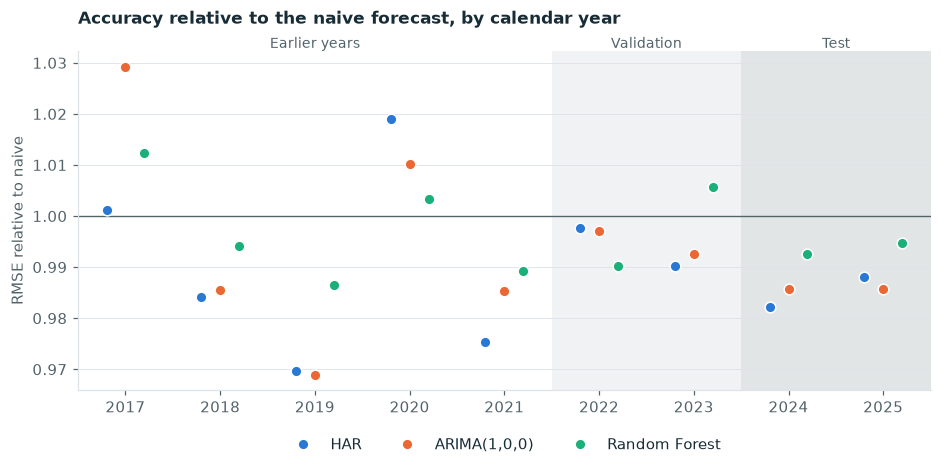

In [7]:
COLOURS = {"HAR": "#2a78d6", ARIMA_NAME: "#eb6834", "Random Forest": "#1baf7a"}
OFFSETS = {"HAR": -0.2, ARIMA_NAME: 0.0, "Random Forest": 0.2}

fig, ax = plt.subplots(figsize=(10, 4))
ax.axhline(1, color=MUTED, linewidth=0.9)
ax.axvspan(2021.5, 2023.5, color=INK, alpha=0.06, linewidth=0)
ax.axvspan(2023.5, 2025.5, color=INK, alpha=0.12, linewidth=0)
for name, colour in COLOURS.items():
    ax.plot(by_year.index + OFFSETS[name], by_year[name], linestyle="none", marker="o", markersize=7,
            color=colour, markeredgecolor="white", markeredgewidth=1, label=name)

top = ax.get_ylim()[1]
for label, centre in [("Earlier years", 2019), ("Validation", 2022.5), ("Test", 2024.5)]:
    ax.text(centre, top, label, ha="center", va="bottom", color=MUTED, fontsize=9)
ax.set_xticks(by_year.index)
ax.set_xlim(2016.5, 2025.5)
ax.grid(axis="x", visible=False)
ax.set_ylabel("RMSE relative to naive")
ax.set_title("Accuracy relative to the naive forecast, by calendar year", pad=18)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
fig.savefig(FIGURES / "robustness_rmse_by_year.png")
plt.show()

**Reading.** HAR and ARIMA have a lower RMSE than naive in 7 of the 9 years, and Random Forest in 6. Neither count is enough for the sign test to reject (p = 0.18 and 0.51). The yearly ratios run from 0.97 to 1.03.

All three models were worse than naive in 2017, the calmest year, and in 2020, the most volatile. A plausible reason, not tested here, is that pulling the forecast towards the usual level works against a model when the VIX stays far from that level for a long stretch.

## 4. Pooled tests against the naive forecast

The Diebold–Mariano test is repeated on two longer samples: all nine years, and 2017–2021 alone, the years that played no part in selecting or testing the models. Settings are as in the protocol, with the number of lags set by the same rule (the smallest integer above the cube root of the sample size).

In [8]:
def lags_for(n):
    return int(np.ceil(n ** (1 / 3)))

SAMPLES = {"2017–2025": slice("2017", "2025"), "2017–2021": slice("2017", "2021")}
LOSSES = {"squared error": "mse", "absolute error": "mae"}

rows = []
for sample_name, sample in SAMPLES.items():
    y = actual[sample]
    for name in FITTED:
        row = {"sample": sample_name, "forecast": name, "days": len(y),
               "RMSE / naive": rmse(y, forecasts.loc[sample, name]) / rmse(y, forecasts.loc[sample, "Naive"]),
               "MAE / naive": mae(y, forecasts.loc[sample, name]) / mae(y, forecasts.loc[sample, "Naive"])}
        for loss_name, criterion in LOSSES.items():
            test = diebold_mariano_test(
                y.to_numpy(), forecasts.loc[sample, name].to_numpy(), forecasts.loc[sample, "Naive"].to_numpy(),
                lags=lags_for(len(y)), criterion=criterion, harvey_adj=True, horizon=1,
            )
            row[f"DM p-value, {loss_name}"] = test.pvalue
        rows.append(row)

pooled = pd.DataFrame(rows)
pooled.round(4)

,sample,forecast,days,RMSE / naive,MAE / naive,"DM p-value, squared error","DM p-value, absolute error"
0,2017–2025,HAR,2262,0.9967,0.9805,0.7399,0.0049
1,2017–2025,"ARIMA(1,0,0)",2262,0.9955,0.9850,0.5567,0.0145
2,2017–2025,Random Forest,2262,0.9967,0.9920,0.3792,0.0917
3,2017–2021,HAR,1259,1.0007,0.9740,0.9626,0.0089
4,2017–2021,"ARIMA(1,0,0)",1259,0.9988,0.9835,0.9132,0.0724
5,2017–2021,Random Forest,1259,0.9982,0.9919,0.7132,0.1621


**Reading and decision.**

Under squared-error loss, none of the pooled tests comes close to rejecting (p = 0.74, 0.56 and 0.38 over 2017–2025). The pooled RMSE advantage over naive is 0.3% to 0.5%, smaller than the 0.6% to 1.4% seen in the test period alone.

**Applying the rule set at the top:** no model meets either condition, so a robust RMSE advantage over the naive forecast is **not established** for HAR, ARIMA or Random Forest. The test-period margin was at the favourable end of what nine years show.

Under absolute-error loss the picture differs. Over 2017–2025 HAR's MAE is 2.0% below naive (p = 0.005) and ARIMA's is 1.5% below (p = 0.014); Random Forest's is 0.8% below (p = 0.09). This was not part of the decision rule, and six tests were run on this sample. With a Bonferroni correction the threshold is 0.05 / 6 = 0.0083, which only HAR passes. On 2017–2021 alone HAR's p-value is 0.009, just above that threshold.

The cautious conclusion is that HAR is slightly more accurate than naive on ordinary days, while the days with large errors, which dominate RMSE, show no reliable difference.

## 5. Is there mean reversion at all?

The Diebold–Mariano test asks whether the forecasts, as actually produced with estimated parameters, differ in accuracy. The Clark–West test asks a different question: whether the larger model contains any true predictive content beyond the benchmark nested inside it. A larger model can contain real signal and still fail to forecast better, because estimating its parameters adds noise.

The test applies to the two linear models, in which the naive forecast is a special case. It is one-sided: a small p-value is evidence that the model adds predictive content. It is not applied to Random Forest, which does not nest the naive forecast in this sense.

In [9]:
rows = []
for sample_name, sample in {"2024–2025 (test)": slice("2024", "2025"), **SAMPLES}.items():
    y = actual[sample]
    for name in ("HAR", ARIMA_NAME):
        statistic, p_value = clark_west(y, forecasts.loc[sample, "Naive"], forecasts.loc[sample, name], lags_for(len(y)))
        rows.append({"sample": sample_name, "forecast": name, "CW statistic": statistic, "one-sided p-value": p_value})

clark_west_table = pd.DataFrame(rows)
clark_west_table.round(4)

,sample,forecast,CW statistic,one-sided p-value
0,2024–2025 (test),HAR,1.5648,0.0588
1,2024–2025 (test),"ARIMA(1,0,0)",2.0762,0.0189
2,2017–2025,HAR,2.6338,0.0042
3,2017–2025,"ARIMA(1,0,0)",2.4057,0.0081
4,2017–2021,HAR,1.9026,0.0285
5,2017–2021,"ARIMA(1,0,0)",1.7398,0.0409


**Reading.** Over 2017–2025 the test rejects for both linear models (p = 0.004 for HAR, 0.008 for ARIMA), and also on 2017–2021 alone (0.029 and 0.041). On the test period it rejects for ARIMA (0.019) and narrowly not for HAR (0.059). The evidence is that the VIX does revert towards its usual level, which agrees with the ADF test in the exploratory analysis.

**A caution.** If the VIX really were a random walk, the regressors in these models would be non-stationary, a situation the standard theory behind this test does not cover. The p-values are indicative, and the agreement with the ADF test, which is designed for that case, is what gives them weight.

**Taken together with the previous section:** the signal is real but small. Once the cost of estimating the model's parameters is included, it is not large enough to produce a reliably lower RMSE than simply using today's close.

## 6. Are the forecasts biased?

The mean forecast error (actual minus forecast) over 2017–2025, with a test that it is zero using a Newey–West standard error.

In [10]:
def mean_with_test(values, lags):
    fit = sm.OLS(values.to_numpy(), np.ones(len(values))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return {"mean error": fit.params[0], "p-value": fit.pvalues[0]}

bias = pd.DataFrame({name: mean_with_test(errors[name], lags_for(len(errors))) for name in forecasts}).T
bias.round(4)

,mean error,p-value
Naive,0.0004,0.9903
HAR,0.0721,0.1186
"ARIMA(1,0,0)",0.0591,0.1702
Random Forest,0.0164,0.6602


**Reading.** No forecast is significantly biased (all p-values are 0.12 or higher). The mean errors of HAR and ARIMA are slightly positive, 0.06 to 0.07 points, meaning forecasts a little too low on average, but this is not distinguishable from zero. The concern raised by the KPSS test, that a shifting average level could make models with a fixed mean systematically wrong, does not show up as bias over these nine years.

## 7. Save the results

In [11]:
residual_table.round(6).to_csv(RESULTS / "robustness_residual_diagnostics.csv", index_label="diagnostic", lineterminator="\n")
by_year.round(6).to_csv(RESULTS / "robustness_by_year.csv", lineterminator="\n")
pooled.round(6).to_csv(RESULTS / "robustness_pooled_tests.csv", index=False, lineterminator="\n")
clark_west_table.round(6).to_csv(RESULTS / "robustness_clark_west.csv", index=False, lineterminator="\n")
print("Saved four robustness tables")

Saved four robustness tables


## 8. What these checks change

| Question | Answer | Effect on the conclusions |
|---|---|---|
| Did the linear models leave structure in their errors? | No reliable short-lag structure; a small amount at lags 6 to 10 | Recorded as a limitation; models unchanged |
| Is the error variance constant? | No | Confirms that robust tests were needed; none needs revising |
| Are the forecasts biased? | No | None |
| Was the RMSE advantage specific to 2024–2025? | Largely: over nine years it is 0.3% to 0.5% and not significant | The main result stands: no robust RMSE advantage over naive |
| Is there mean reversion at all? | Yes, on the Clark–West and ADF tests | Explains the result: the signal exists but is too weak to use |
| Anything new? | HAR's MAE is about 2% below naive over nine years and survives a multiple-testing correction | An exploratory finding, not a confirmed one |

The answer to the main research question is unchanged. Random Forest does not improve on ARIMA or the naive forecast. Across nine years it beats naive in the fewest years and has the smallest MAE improvement of the three fitted models.